# Projet Leyenda - Livrable 1

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:
![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Dans ce ***premier livrable***, nous créeons un CNN via la bibliothéque tensorFlow, pour cela nous utilisons un dataset que nous importons et effectuant un pré traitement, en créeant des dossiers dans le dossier mère : *process* True et False, permettant de regroupé les groupes d'images pour ensuite les splité en différents sets : Train, Test et Valid. 

Détail du ***Livrable 1:***
- Le code TensorFlow ainsi qu'un schéma de l'architecture du réseau de neurones. Toutes les parties doivent être détaillée dans le notebook : les paramètre du réseau, la fonction de perte ainsi que l'algorithme d'optimisation utilisé pour l’entraînement.
- Un graphique contenant l'évolution de l'erreur d’entraînement ainsi que de l'erreur de test et l'évolution de l'accuracy pour ces deux datasets.
- L'analyse de ces résultats, notamment le compromis entre biais et variance (ou sur-apprentissage et sous-apprentissage).
- Une description des méthodes potentiellement utilisables pour améliorer les compromis biais/variance : technique de régularisation, drop out, early-stopping, ...

***Pour le CNN , nous créeons l'architecture suivante:***
- Importation du dataset et la division en 75%/15%/10%
- La normalisation des données /255 pour que les valeurs soit comprise entre 0.0 et 1.0
- Nous initialiation le modèle avec plusieurs couches de Convulation (conv2d) et pooling (Maxpooling2D)
- Nous transformons ensuite l'image en un vecteur de une dimension avec Flatten
- Pour finir avec les dense Layers et une sortie binaire avec la formule mathématique utilisé ici sigmoid


# Etape 1:
### Schéma de notre architecture :

### Importation des librairies

In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from DL_dataset import *

### Les paramètres et hyperparametres utilisé:
- Epoch :
- $\lambda$ :
- learning rate :
- BATCH_SIZE : 
- Dropout :
- Patience :
- Train et Test split:
- img_size:

In [23]:
Epoch=10
lambda_l2=0.001
learning_rate=0.01
BATCH_SIZE=32
Dropout:0.1
Patience=5
train_split=0.75
test_split=0.25
img_size=64

### Téléchargement et préprocessing des données
Chaque step peut etre activé ou non, la première est le téléchargement des fichiers zip, la deuxieme étape est de dézipé les fichiers et la dernière est de fusionner les datasets dans le dossier processing avec un sous dossier True pour les photo et les autres Dataset dans False.

In [24]:
step_DL=True      
step_unzip=True
step_process=True

urls=[
    "https://drive.google.com/file/d/1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX/view?usp=sharing",
    "https://drive.google.com/file/d/1SvFZNAQ7rD5IQUGNwbuKfBb0ateQmOYy/view?usp=sharing",
    "https://drive.google.com/file/d/1J-WupkQTuwmniUiO-E0rMQzsl2Pi1J5o/view?usp=sharing",
    "https://drive.google.com/file/d/1Khs9gpNywmoAfQMQ1Z7_ggge5wZepKj_/view?usp=sharing",
    "https://drive.google.com/file/d/16CatMjdgNhGkvlss5lmpzvf-AbV-6Q8T/view?usp=sharing"
]

folder_raw = Path(f"./data/raw")
folder_process = Path(f"./data/processing")

if not os.path.exists(folder_raw):
    os.makedirs(folder_raw)

if not os.path.exists(folder_process):
    os.makedirs(folder_process)

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

if step_process==True:
    file_list=copy(folder_process)

File download:


Downloading...
From (original): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX
From (redirected): https://drive.google.com/uc?id=1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX&confirm=t&uuid=1a8dac2e-75b0-4607-8627-0972a66ec61e
To: c:\Users\chris\Documents\CESI annee 2026-2027 FISE A5\Deep learning\Cnn-and-RNN\data\raw\downloaded_file1Gco_h5WCkqHJhVzUf5nOXVWa7wjKv-oX.zip
 93%|█████████▎| 4.29G/4.61G [12:11<00:53, 5.86MB/s]


KeyboardInterrupt: 

### Division des datasets en un dataset Train et False

In [25]:
dossier_racine = Path(f"./data/processing/")
train_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= 1-train_split,
  subset =  "training",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size)
)

test_set = tf.keras.preprocessing.image_dataset_from_directory(
  dossier_racine,
  validation_split= test_split,
  subset =  "validation",
  seed=42,
  batch_size=BATCH_SIZE,
  image_size=(img_size,img_size),
)

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Found 62812 files belonging to 2 classes.
Using 47109 files for training.
Found 62812 files belonging to 2 classes.
Using 15703 files for validation.


### Création de l'architecture du modèle

In [26]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    #Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.1),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model = keras.Sequential(model_layers)

### Choix de la métrique et de l'optimizer
On utilise un optimiser pour mettre à jour les poids en utilisant la descente de gradient lors de la backpropagation, le plus souvent on utilise l'agorithme Adam qui mets à jour automatiquement le Learning rate pour chaque poids en améliorant la vitesse et les performances d'entrainement. Lorsqu'on compile le modèle avec TensorFlow, on choisit la métrique que l'on peut observé, ici l'accuracy de notre modèle. La loss fonction est utilisé pour calculé la différence entre les prédictions de notre modèle et les véritables images. Plusieurs méthodes sont disponible pour le CNN:

- Binary Cross-Entropy (Pour la classification binaire)
- Categorical Cross-Entropy (Pour la classification de plusieurs classes)
- Sparse Categorical Crossentropy (Pour la classification de plusieurs classes, mais les labels sont des numéros entier 1,2 etc...)

On va donc utiliser ici la ***Binary Cross-Entropy***.

In [27]:
model.compile(optimizer ="adam",  #A COMPLETER
              loss =  "binary_crossentropy",
              metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,281 (6.20 MB)

 Trainable params: 1,625,281 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

### Lancement du modèle
Avec la fonction ***Model.fit*** va permettre de lancer l'entrainement avec différents paramètres tels que le nombre d'epochs, est le nombre de fois que le modèle s'entraine, ***validation_data*** est quant à lui, la partie avec lequel la data sera testé, ici le dataset défini plus haut *test_set*.

In [28]:
history = model.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 185s 92ms/step - accuracy: 0.8736 - loss: 0.2663 - val_accuracy: 0.9018 - val_loss: 0.2164
Epoch 2/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 124s 84ms/step - accuracy: 0.9126 - loss: 0.1953 - val_accuracy: 0.9209 - val_loss: 0.1839
Epoch 3/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 143s 97ms/step - accuracy: 0.9322 - loss: 0.1595 - val_accuracy: 0.9331 - val_loss: 0.1645
Epoch 4/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 98s 66ms/step - accuracy: 0.9477 - loss: 0.1260 - val_accuracy: 0.9341 - val_loss: 0.1580
Epoch 5/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 78s 53ms/step - accuracy: 0.9620 - loss: 0.0960 - val_accuracy: 0.9392 - val_loss: 0.1611
Epoch 6/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 79s 53ms/step - accuracy: 0.9744 - loss: 0.0655 - val_accuracy: 0.9332 - val_loss: 0.1876
Epoch 7/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 78s 53ms/step - accuracy: 0.9835 - loss: 0.0441 - val_accuracy: 0.9329 - val_loss: 0.2325
Epoch 8/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 76s 52ms/step - accuracy: 0.989

# Etape 2:
### Graphique des résultats obtenu pour le modèle:
Dans ce graphique, nous regardons l'accuracy et la fonction de perte dans ce graphique au cours de l'entrainement à chaque epoch.

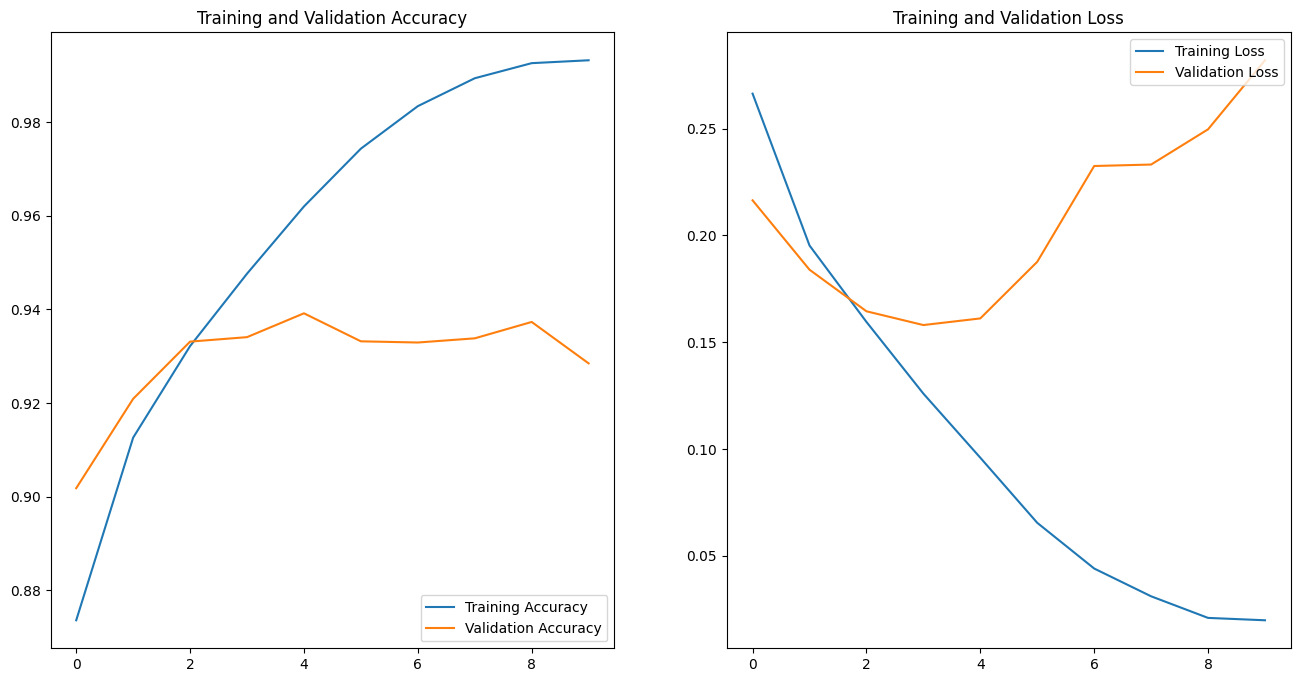

In [29]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(Epoch)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

***Résultat:*** En observant les deux graphs obtenus, on remarque une grosse différence dans la fonction de perte entre celui de Train et celui de validation, ce qui indique une grande variance donc un overfitting, pour résoudre ce problème, nous utiliserons différents paramètres à notre disposition pour pouvoir régler cet overfitting tout en évitant l'under-fitting.

# Etape3
### Comparaison entre les différents modèles avec différents paramètres:

In [ ]:
model_layers = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    # Normalisation
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), 
    layers.Dense(1, activation='sigmoid')
])

model_dropout = keras.Sequential(model_layers)

model_dropout.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [ ]:
history_dropout = model_dropout.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/25


1473/1473 ━━━━━━━━━━━━━━━━━━━━ 246s 167ms/step - accuracy: 0.9766 - loss: 0.0617 - val_accuracy: 0.9385 - val_loss: 0.1819
Epoch 2/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 47s 32ms/step - accuracy: 0.9795 - loss: 0.0538 - val_accuracy: 0.9378 - val_loss: 0.2172
Epoch 3/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 46s 32ms/step - accuracy: 0.9827 - loss: 0.0466 - val_accuracy: 0.9350 - val_loss: 0.2390
Epoch 4/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.9835 - loss: 0.0451 - val_accuracy: 0.9381 - val_loss: 0.2248
Epoch 5/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 221s 150ms/step - accuracy: 0.9841 - loss: 0.0426 - val_accuracy: 0.9344 - val_loss: 0.2430
Epoch 6/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 241s 163ms/step - accuracy: 0.9863 - loss: 0.0359 - val_accuracy: 0.9391 - val_loss: 0.2578
Epoch 7/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 46s 31ms/step - accuracy: 0.9853 - loss: 0.0377 - val_accuracy: 0.9378 - val_loss: 0.2687
Epoch 8/25
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 46s 31ms/step - accuracy: 0.9859 - loss

KeyboardInterrupt: 

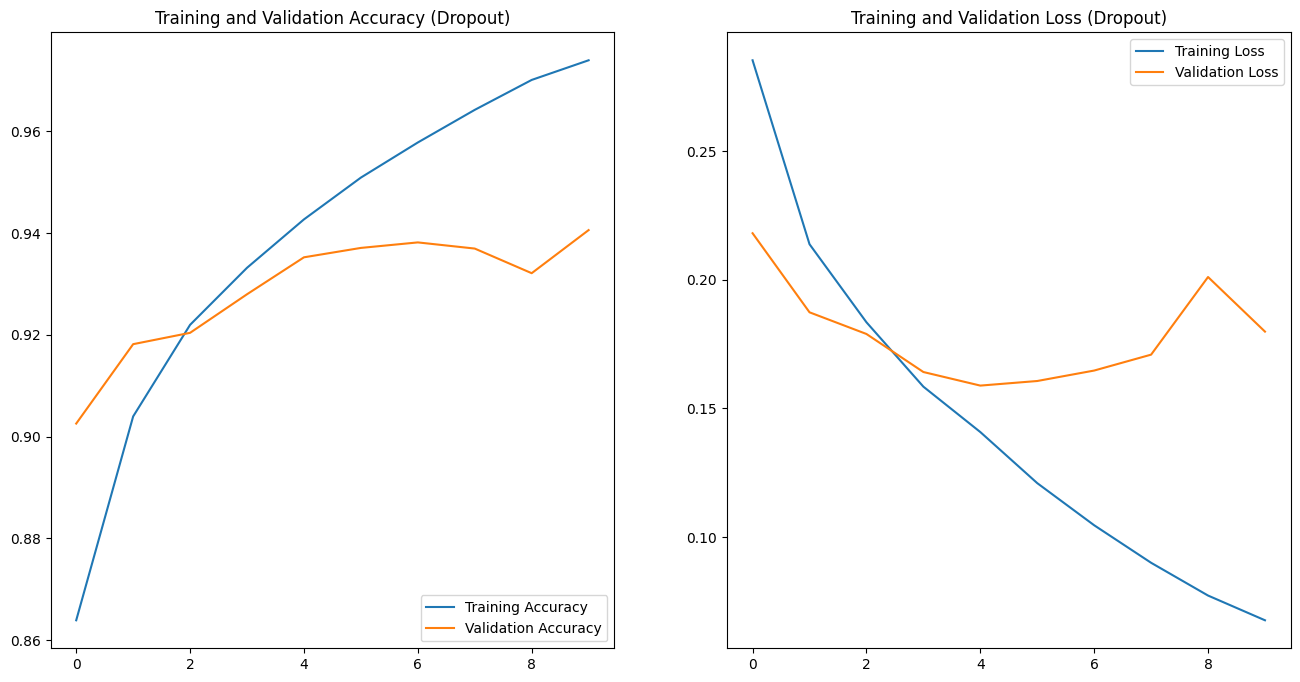

In [ ]:
acc = history_dropout.history['accuracy']
val_acc = history_dropout.history['val_accuracy']

loss = history_dropout.history['loss']
val_loss = history_dropout.history['val_loss']

epochs_range = range(Epoch)



plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy (Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss (Dropout)')
plt.show()

In [34]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

model_layers_final = [
    keras.Input(shape=(None, None, 3)), 
    
    layers.Resizing(img_size, img_size),
    
    data_augmentation, 
    
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
]

if img_size == 256: 
    model_layers_final.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
    ])

model_layers_final.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), 
    layers.Dense(1, activation='sigmoid')
])

model_final = keras.Sequential(model_layers_final)

model_final.compile(optimizer="adam", 
              loss="binary_crossentropy",
              metrics=['accuracy'])

In [ ]:
history_final = model_final.fit(train_set, epochs=Epoch, validation_data=test_set)

Epoch 1/10


c:\Users\chris\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1473/1473 ━━━━━━━━━━━━━━━━━━━━ 533s 361ms/step - accuracy: 0.8189 - loss: 0.3719 - val_accuracy: 0.8255 - val_loss: 0.3219
Epoch 2/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 137s 93ms/step - accuracy: 0.8643 - loss: 0.3055 - val_accuracy: 0.8963 - val_loss: 0.2368
Epoch 3/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 57s 39ms/step - accuracy: 0.8813 - loss: 0.2749 - val_accuracy: 0.8818 - val_loss: 0.2445
Epoch 4/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 57s 39ms/step - accuracy: 0.8916 - loss: 0.2537 - val_accuracy: 0.8861 - val_loss: 0.2412
Epoch 5/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 185s 126ms/step - accuracy: 0.8962 - loss: 0.2448 - val_accuracy: 0.9224 - val_loss: 0.1886
Epoch 6/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 166s 113ms/step - accuracy: 0.9018 - loss: 0.2343 - val_accuracy: 0.8963 - val_loss: 0.2240
Epoch 7/10
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 697s 474ms/step - accuracy: 0.9053 - loss: 0.2247 - val_accuracy: 0.9063 - val_loss: 0.2106
Epoch 8/10
 903/1473 ━━━━━━━━━━━━━━━━━━━━ 5:31 581ms/step - accuracy: 0.9066 -

In [ ]:
acc_final = history_final.history['accuracy']
val_acc_final = history_final.history['val_accuracy']

loss_final = history_final.history['loss']
val_loss_final = history_final.history['val_loss']

epochs_range = range(Epoch)



plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_final, label='Training Accuracy')
plt.plot(epochs_range, val_acc_final, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy (Aug + Dropout)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_final, label='Training Loss')
plt.plot(epochs_range, val_loss_final, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss (Aug + Dropout)')
plt.show()

# Etape 4
Pour faire face à l'under-fitting et d'over-fitting, nous avons utilisé plusieurs principes très connu et disponible sur tensorflow comme ***Dropout***, qui va nous servir pour contrer l'over-fitting en désactivent certains neurones, nous avons testés plusieurs valeurs comme 0.1, 0.2 et 0.4. Les deux meilleurs résultats ont été avec 0.1 et 0.2. Comme autre méthodes, nous avons rajouté dans les dense layer, ***un l2_regularization*** Va appliqué une pénalité sur les poids trop grand, cela force pendant l'optimisation des poids se rapproche de 0, la valeur pour définir la puissance de cette pénalité est choisit via l'hyperparamètres **lambda ($\lambda$**) la puissance de cette pénalité. La dernière technique est le ***Early stopping Callback***, on l'utilise pour stopper l'entrainement du modèle quand la valeur cible ne s'améliore pas, on défini un hyperparamètre patience qui s'y active après x fois défini est atteinte et que pendant cette période il y a eu aucune amélioration et limité l'overfitting car le modèle est devenu "paraisseux".
Pour l'under-fitting, nous jouons avec les différents hyperparametres et faisons aussi la data augmentation qui permet d'avoir dans le train set un nombre similaire de True et False, pour que son entrainement soit claire et détaillé.